# Cuaderno 03 — Ejercicio 3 (ensemble clasificador), Ejercicio 4 (bagging) y Ejercicio 5 (RandomForest vs. XGBoost)

**Tarea de ejecución 03 — Aplicar modelos CART y ensamblados**

**Curso:** Aprendizaje de Máquina (UNAP, IX ciclo, grupo B)
**Docente:** Ing. Fernandez Chambi Mayenka
**Estudiante:** Cristian Junior Cunurana Calderón

---

## Objetivos

- **Ejercicio 3.** Entrenar un **modelo ensemble clasificador** sobre `breast_cancer` y comparar su
  eficiencia con la de un **modelo individual** (el mejor árbol de decisión y la regresión logística
  del ejercicio 1). Determinar cuál es mejor.
- **Ejercicio 4.** Entrenar un modelo de **bagging** y compararlo con un **modelo individual**,
  tanto en regresión (`auto_mpg`) como en clasificación (`breast_cancer`). Verificar si el bagging
  reduce la varianza del estimador base.
- **Ejercicio 5.** Comparar **RandomForest** frente a **XGBoost** en el mismo problema de
  clasificación, ajustando los hiperparámetros de ambos con el mismo protocolo.

## Protocolo experimental

| Aspecto | Decisión adoptada |
|---|---|
| Partición | 80 % entrenamiento / 20 % prueba (estratificada en clasificación), semilla 42 |
| Validación | 5 particiones (`StratifiedKFold` / `KFold`), `shuffle=True`, semilla 42 |
| Selección | `GridSearchCV` **solo sobre el conjunto de entrenamiento** |
| Métricas (clasificación) | Exactitud, precisión, exhaustividad, F1 y AUC-ROC (clase positiva = *maligno*) |
| Métricas (regresión) | RMSE, MAE y $R^2$ |
| Preprocesamiento | Incluido dentro de `Pipeline`; se ajusta únicamente con datos de entrenamiento |
| Comparaciones | Todos los modelos se evalúan sobre **las mismas** observaciones de prueba |
| Implementación | `xgboost` 3.4.1 con `tree_method="hist"` para boosting acelerado |

In [1]:
import sys
import time
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd() / "cuadernos"))
if not (Path.cwd() / "cuadernos" / "comun.py").exists():
    sys.path.insert(0, str(Path.cwd().parent / "cuadernos"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import (
    BaggingClassifier,
    BaggingRegressor,
    GradientBoostingClassifier,
    RandomForestClassifier,
    RandomForestRegressor,
    VotingClassifier,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

from xgboost import XGBClassifier

from comun import (
    RAIZ,
    SEMILLA,
    PALETA,
    aplicar_estilo,
    cargar_auto_mpg,
    cargar_breast_cancer,
    fijar_semilla,
    guardar_csv,
    guardar_json,
)

warnings.filterwarnings("ignore", category=FutureWarning)
aplicar_estilo()
fijar_semilla(SEMILLA)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 175)

FIG = RAIZ / "figuras"
RES = RAIZ / "resultados"
print("RAIZ:", RAIZ)

RAIZ: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 3


## Parte I — Ejercicio 3: modelo ensemble clasificador frente al modelo individual

### 3.1 Datos y partición

Se reutiliza la partición del ejercicio 1: **455** observaciones de entrenamiento y **114** de
prueba, estratificadas por clase. La clase positiva es *maligno* (`1`).

In [2]:
X_bc, y_bc, nombres_bc = cargar_breast_cancer()

X_tr, X_te, y_tr, y_te = train_test_split(
    X_bc, y_bc, test_size=0.20, random_state=SEMILLA, stratify=y_bc
)

cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

print(f"Entrenamiento: {X_tr.shape[0]} | Prueba: {X_te.shape[0]}")
print(f"Malignos — entrenamiento: {int(y_tr.sum())} | prueba: {int(y_te.sum())}")

Entrenamiento: 455 | Prueba: 114
Malignos — entrenamiento: 285 | prueba: 72


### 3.2 Modelos individuales de referencia

Se vuelven a ajustar los dos modelos individuales del ejercicio 1 con el mismo protocolo, de
modo que el cuaderno sea reproducible por sí mismo:

- **Regresión logística** con estandarización dentro del `Pipeline`.
- **Árboles de decisión** con criterio `gini` y `entropy`, buscando profundidad máxima y mínimo
  de muestras por hoja.

In [3]:
pipe_log = Pipeline([("escalador", StandardScaler()),
                     ("clasificador", LogisticRegression(max_iter=5000, random_state=SEMILLA))])
malla_log = {"clasificador__C": [0.01, 0.1, 1.0, 10.0, 100.0]}

busqueda_log = GridSearchCV(pipe_log, malla_log, cv=cv_clf, scoring="f1", n_jobs=-1)
t0 = time.perf_counter()
busqueda_log.fit(X_tr, y_tr)
t1 = time.perf_counter()
modelo_log = busqueda_log.best_estimator_
print(f"[logística] mejor F1 CV = {busqueda_log.best_score_:.4f} | {busqueda_log.best_params_} "
      f"| tiempo = {t1 - t0:.2f} s")

profundidades = [2, 3, 4, 5, 6, 8, None]
minimos_hoja = [1, 2, 3, 5, 10]

arboles_individuales = {}
for criterio in ("gini", "entropy"):
    pipe = Pipeline([("arbol", DecisionTreeClassifier(criterion=criterio, random_state=SEMILLA))])
    malla = {"arbol__max_depth": profundidades, "arbol__min_samples_leaf": minimos_hoja}
    busqueda = GridSearchCV(pipe, malla, cv=cv_clf, scoring="f1", n_jobs=-1)
    t0 = time.perf_counter()
    busqueda.fit(X_tr, y_tr)
    t1 = time.perf_counter()
    arboles_individuales[criterio] = busqueda.best_estimator_
    print(f"[{criterio}] mejor F1 CV = {busqueda.best_score_:.4f} | {busqueda.best_params_} "
          f"| tiempo = {t1 - t0:.2f} s")

modelo_gini = arboles_individuales["gini"]
modelo_entropy = arboles_individuales["entropy"]

[logística] mejor F1 CV = 0.9861 | {'clasificador__C': 0.1} | tiempo = 2.69 s


[gini] mejor F1 CV = 0.9460 | {'arbol__max_depth': 3, 'arbol__min_samples_leaf': 5} | tiempo = 0.32 s


[entropy] mejor F1 CV = 0.9509 | {'arbol__max_depth': 4, 'arbol__min_samples_leaf': 5} | tiempo = 0.25 s


### 3.3 Modelos ensemble

Se entrenan tres familias de ensembles con el mismo protocolo de búsqueda:

1. **Voting blando** (`VotingClassifier`, `voting="soft"`): combina las probabilidades de la
   regresión logística y de los dos árboles, es decir, tres modelos con sesgos distintos.
   La agregación por promedio de probabilidades reduce la varianza sin introducir sesgo
   sistemático.
2. **RandomForest**: bagging de árboles con submuestreo de variables, que además descorrelaciona
   los árboles base.
3. **GradientBoosting**:boosting secuencial, donde cada árbol corrige los errores residuales de
   los anteriores.

El ensemble por votación se construye sobre los modelos individuales **ya ajustados** con los
hiperparámetros_optimos del ejercicio 3.2, de modo que la comparación sea justa.

In [4]:
modelo_voting = VotingClassifier(
    estimators=[("logistica", modelo_log),
                ("arbol_gini", modelo_gini),
                ("arbol_entropy", modelo_entropy)],
    voting="soft",
    n_jobs=-1,
)

modelo_rf = RandomForestClassifier(random_state=SEMILLA, n_jobs=-1)
malla_rf = {
    "n_estimators": [200, 500],
    "max_depth": [None, 4, 8],
    "min_samples_leaf": [1, 3, 5],
    "max_features": ["sqrt", 0.5],
}

modelo_gb = GradientBoostingClassifier(random_state=SEMILLA)
malla_gb = {
    "n_estimators": [100, 300],
    "learning_rate": [0.05, 0.1, 0.2],
    "max_depth": [2, 3, 5],
}

busqueda_voting = GridSearchCV(modelo_voting, {}, cv=cv_clf, scoring="f1", n_jobs=-1)
t0 = time.perf_counter()
busqueda_voting.fit(X_tr, y_tr)
t1 = time.perf_counter()
mejor_voting = busqueda_voting.best_estimator_
print(f"[voting soft] mejor F1 CV = {busqueda_voting.best_score_:.4f} | tiempo = {t1 - t0:.2f} s")

busqueda_rf = GridSearchCV(modelo_rf, malla_rf, cv=cv_clf, scoring="f1", n_jobs=-1)
t0 = time.perf_counter()
busqueda_rf.fit(X_tr, y_tr)
t1 = time.perf_counter()
mejor_rf = busqueda_rf.best_estimator_
print(f"[random forest] mejor F1 CV = {busqueda_rf.best_score_:.4f} | {busqueda_rf.best_params_} "
      f"| tiempo = {t1 - t0:.2f} s")

busqueda_gb = GridSearchCV(modelo_gb, malla_gb, cv=cv_clf, scoring="f1", n_jobs=-1)
t0 = time.perf_counter()
busqueda_gb.fit(X_tr, y_tr)
t1 = time.perf_counter()
mejor_gb = busqueda_gb.best_estimator_
print(f"[gradient boosting] mejor F1 CV = {busqueda_gb.best_score_:.4f} | {busqueda_gb.best_params_} "
      f"| tiempo = {t1 - t0:.2f} s")

[voting soft] mejor F1 CV = 0.9564 | tiempo = 0.09 s


/home/ccunurana/Documentos/Aprendizaje Profundo/.venv/lib64/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/ccunurana/Documentos/Aprendizaje Profundo/.venv/lib64/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/ccunurana/Documentos/Aprendizaje Profundo/.venv/lib64/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib 

/home/ccunurana/Documentos/Aprendizaje Profundo/.venv/lib64/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/ccunurana/Documentos/Aprendizaje Profundo/.venv/lib64/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/ccunurana/Documentos/Aprendizaje Profundo/.venv/lib64/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib 

/home/ccunurana/Documentos/Aprendizaje Profundo/.venv/lib64/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/ccunurana/Documentos/Aprendizaje Profundo/.venv/lib64/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/ccunurana/Documentos/Aprendizaje Profundo/.venv/lib64/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib 

[random forest] mejor F1 CV = 0.9700 | {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 200} | tiempo = 23.24 s


[gradient boosting] mejor F1 CV = 0.9789 | {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 300} | tiempo = 7.22 s


### 3.4 Evaluación de los modelos sobre el conjunto de prueba

Todos los modelos se evalúan sobre las **mismas** 114 observaciones de prueba.

In [5]:
modelos_ej3 = {
    "regresion_logistica": modelo_log,
    "arbol_gini": modelo_gini,
    "arbol_entropy": modelo_entropy,
    "voting_soft": mejor_voting,
    "random_forest": mejor_rf,
    "gradient_boosting": mejor_gb,
    "dummy": DummyClassifier(strategy="most_frequent", random_state=SEMILLA).fit(X_tr, y_tr),
}


def evaluar_clasificador(nombre, estimador, X_ent, y_ent, X_pru, y_pru):
    y_pred = estimador.predict(X_pru)
    y_prob = estimador.predict_proba(X_pru)[:, 1]
    return {
        "modelo": nombre,
        "exactitud": float(accuracy_score(y_pru, y_pred)),
        "precision": float(precision_score(y_pru, y_pred, zero_division=0)),
        "exhaustividad": float(recall_score(y_pru, y_pred, zero_division=0)),
        "f1": float(f1_score(y_pru, y_pred, zero_division=0)),
        "auc_roc": float(roc_auc_score(y_pru, y_prob)),
        "f1_entrenamiento": float(f1_score(y_ent, estimador.predict(X_ent), zero_division=0)),
        "accuracy_entrenamiento": float(accuracy_score(y_ent, estimador.predict(X_ent))),
    }


filas_ej3 = [evaluar_clasificador(nombre, est, X_tr, y_tr, X_te, y_te)
             for nombre, est in modelos_ej3.items()]
metricas_ej3 = pd.DataFrame(filas_ej3).set_index("modelo")
print(metricas_ej3.round(4).to_string())
guardar_csv(metricas_ej3.reset_index(), "ejercicio3_metricas.csv")

                     exactitud  precision  exhaustividad      f1  auc_roc  f1_entrenamiento  accuracy_entrenamiento
modelo                                                                                                             
regresion_logistica     0.9737     0.9726         0.9861  0.9793   0.9957            0.9895                  0.9868
arbol_gini              0.9386     0.9452         0.9583  0.9517   0.9439            0.9792                  0.9736
arbol_entropy           0.8772     0.9531         0.8472  0.8971   0.9593            0.9788                  0.9736
voting_soft             0.9474     0.9583         0.9583  0.9583   0.9878            0.9895                  0.9868
random_forest           0.9561     0.9589         0.9722  0.9655   0.9931            1.0000                  1.0000
gradient_boosting       0.9474     0.9459         0.9722  0.9589   0.9917            1.0000                  1.0000
dummy                   0.6316     0.6316         1.0000  0.7742   0.500

PosixPath('/home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 3/resultados/ejercicio3_metricas.csv')

### 3.5 Estabilidad: validación cruzada y particiones repetidas

Un único corte aleatorio puede favorecer accidentalmente a un modelo. Por eso se evalúa cada
modelo con **validación cruzada de 5 particiones** (media ± desviación estándar del F1) y con
**7 particiones 80/20** independientes sobre las mismas observaciones de prueba.

In [6]:
nombres_cv = ["regresion_logistica", "arbol_gini", "voting_soft", "random_forest", "gradient_boosting"]

cv_tabla = []
for nombre in nombres_cv:
    puntajes = cross_validate(
        modelos_ej3[nombre], X_tr, y_tr, cv=cv_clf,
        scoring=["f1", "roc_auc", "accuracy"], n_jobs=-1,
    )
    cv_tabla.append({
        "modelo": nombre,
        "f1_cv_media": float(np.mean(puntajes["test_f1"])),
        "f1_cv_de": float(np.std(puntajes["test_f1"])),
        "auc_cv_media": float(np.mean(puntajes["test_roc_auc"])),
        "auc_cv_de": float(np.std(puntajes["test_roc_auc"])),
        "accuracy_cv_media": float(np.mean(puntajes["test_accuracy"])),
    })

tabla_cv_ej3 = pd.DataFrame(cv_tabla).set_index("modelo")
print("Validación cruzada (5 particiones) sobre el conjunto de entrenamiento:")
print(tabla_cv_ej3.round(4).to_string())
guardar_csv(tabla_cv_ej3.reset_index(), "ejercicio3_cv.csv")

semillas = [SEMILLA, 7, 13, 21, 99, 123, 2026]
registros_ej3 = []
for semilla in semillas:
    X_tr_s, X_te_s, y_tr_s, y_te_s = train_test_split(
        X_bc, y_bc, test_size=0.20, random_state=semilla, stratify=y_bc
    )
    for nombre in nombres_cv:
        copia = clone(modelos_ej3[nombre]).fit(X_tr_s, y_tr_s)
        y_pred = copia.predict(X_te_s)
        registros_ej3.append({
            "semilla": semilla,
            "modelo": nombre,
            "f1": float(f1_score(y_te_s, y_pred, zero_division=0)),
            "exactitud": float(accuracy_score(y_te_s, y_pred)),
            "auc_roc": float(roc_auc_score(y_te_s, copia.predict_proba(X_te_s)[:, 1])),
        })

tabla_rep_ej3 = pd.DataFrame(registros_ej3)
resumen_rep_ej3 = tabla_rep_ej3.groupby("modelo").agg(
    f1_media=("f1", "mean"), f1_de=("f1", "std"),
    f1_min=("f1", "min"), f1_max=("f1", "max"),
    auc_media=("auc_roc", "mean"), auc_de=("auc_roc", "std"),
).round(4)
print("\nValidación repetida (7 particiones 80/20 con semillas distintas):")
print(resumen_rep_ej3.to_string())
guardar_csv(tabla_rep_ej3, "ejercicio3_repeticiones.csv")

Validación cruzada (5 particiones) sobre el conjunto de entrenamiento:
                     f1_cv_media  f1_cv_de  auc_cv_media  auc_cv_de  accuracy_cv_media
modelo                                                                                
regresion_logistica       0.9861    0.0042        0.9951     0.0046             0.9824
arbol_gini                0.9460    0.0124        0.9481     0.0221             0.9319
voting_soft               0.9564    0.0122        0.9902     0.0067             0.9451
random_forest             0.9700    0.0146        0.9894     0.0086             0.9626
gradient_boosting         0.9789    0.0164        0.9925     0.0071             0.9736



Validación repetida (7 particiones 80/20 con semillas distintas):
                     f1_media   f1_de  f1_min  f1_max  auc_media  auc_de
modelo                                                                  
arbol_gini             0.9477  0.0139  0.9262  0.9722     0.9585  0.0156
gradient_boosting      0.9685  0.0156  0.9452  0.9931     0.9944  0.0030
random_forest          0.9674  0.0075  0.9589  0.9790     0.9922  0.0055
regresion_logistica    0.9794  0.0040  0.9726  0.9863     0.9970  0.0018
voting_soft            0.9606  0.0090  0.9444  0.9726     0.9923  0.0042


PosixPath('/home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 3/resultados/ejercicio3_repeticiones.csv')

### 3.6 Respuesta al ejercicio 3

La comparación se realiza sobre el conjunto de prueba y se contrasta con las dos estimaciones
independientes (validación cruzada y particiones repetidas) para evitar conclusiones debidas al
azar de una única división.

In [7]:
ind = metricas_ej3.loc["regresion_logistica"]
arb = metricas_ej3.loc["arbol_gini"]
ens = metricas_ej3.loc["voting_soft"]
rf = metricas_ej3.loc["random_forest"]
gb = metricas_ej3.loc["gradient_boosting"]
dummy = metricas_ej3.loc["dummy"]

print("=" * 78)
print("PREGUNTA 3 — Ensemble clasificador vs. modelo individual (conjunto de prueba)")
print("=" * 78)
print(f"F1 de prueba:   voting {ens.f1:.4f} | RF {rf.f1:.4f} | GB {gb.f1:.4f} "
      f"| logística {ind.f1:.4f} | árbol gini {arb.f1:.4f} | dummy {dummy.f1:.4f}")
print(f"Exactitud:      voting {ens.exactitud:.4f} | RF {rf.exactitud:.4f} | GB {gb.exactitud:.4f} "
      f"| logística {ind.exactitud:.4f} | árbol gini {arb.exactitud:.4f}")
print(f"AUC-ROC:        voting {ens.auc_roc:.4f} | RF {rf.auc_roc:.4f} | GB {gb.auc_roc:.4f} "
      f"| logística {ind.auc_roc:.4f} | árbol gini {arb.auc_roc:.4f}")

ensembles_ej3 = ["voting_soft", "random_forest", "gradient_boosting"]
individuales_ej3 = ["regresion_logistica", "arbol_gini", "arbol_entropy"]
mejor_ensamble = metricas_ej3.loc[ensembles_ej3].f1.idxmax()
mejor_individual = metricas_ej3.loc[individuales_ej3].f1.idxmax()
print(f"\nMejor ensemble: {mejor_ensamble} (F1 = {metricas_ej3.loc[mejor_ensamble, 'f1']:.4f})")
print(f"Mejor modelo individual: {mejor_individual} "
      f"(F1 = {metricas_ej3.loc[mejor_individual, 'f1']:.4f})")
print(f"Mejora del ensemble sobre el mejor individual: "
      f"{metricas_ej3.loc[mejor_ensamble, 'f1'] - metricas_ej3.loc[mejor_individual, 'f1']:+.4f} F1")

print("\nEstabilidad (F1 en 7 particiones independientes):")
for nombre in nombres_cv:
    fila = resumen_rep_ej3.loc[nombre]
    print(f"  {nombre:<22} {fila.f1_media:.4f} ± {fila.f1_de:.4f}  "
          f"[{fila.f1_min:.4f} – {fila.f1_max:.4f}]")

PREGUNTA 3 — Ensemble clasificador vs. modelo individual (conjunto de prueba)
F1 de prueba:   voting 0.9583 | RF 0.9655 | GB 0.9589 | logística 0.9793 | árbol gini 0.9517 | dummy 0.7742
Exactitud:      voting 0.9474 | RF 0.9561 | GB 0.9474 | logística 0.9737 | árbol gini 0.9386
AUC-ROC:        voting 0.9878 | RF 0.9931 | GB 0.9917 | logística 0.9957 | árbol gini 0.9439

Mejor ensemble: random_forest (F1 = 0.9655)
Mejor modelo individual: regresion_logistica (F1 = 0.9793)
Mejora del ensemble sobre el mejor individual: -0.0138 F1

Estabilidad (F1 en 7 particiones independientes):
  regresion_logistica    0.9794 ± 0.0040  [0.9726 – 0.9863]
  arbol_gini             0.9477 ± 0.0139  [0.9262 – 0.9722]
  voting_soft            0.9606 ± 0.0090  [0.9444 – 0.9726]
  random_forest          0.9674 ± 0.0075  [0.9589 – 0.9790]
  gradient_boosting      0.9685 ± 0.0156  [0.9452 – 0.9931]


### 3.7 Figuras del ejercicio 3

**Figura 17.** Comparación de métricas de clasificación (modelo individual frente a ensembles).
**Figura 18.** Matrices de confusión sobre el conjunto de prueba.
**Figura 19.** Curvas ROC comparadas.

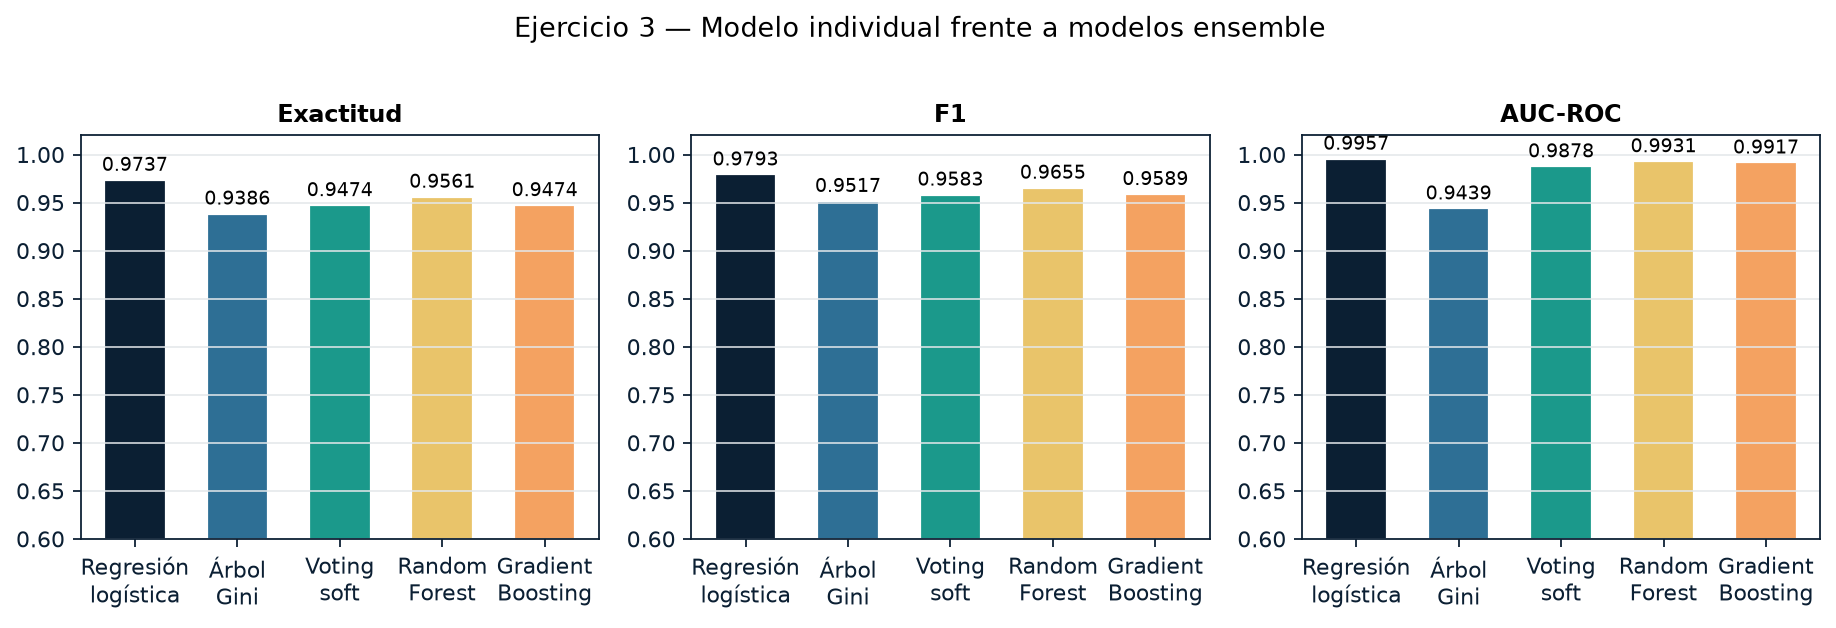

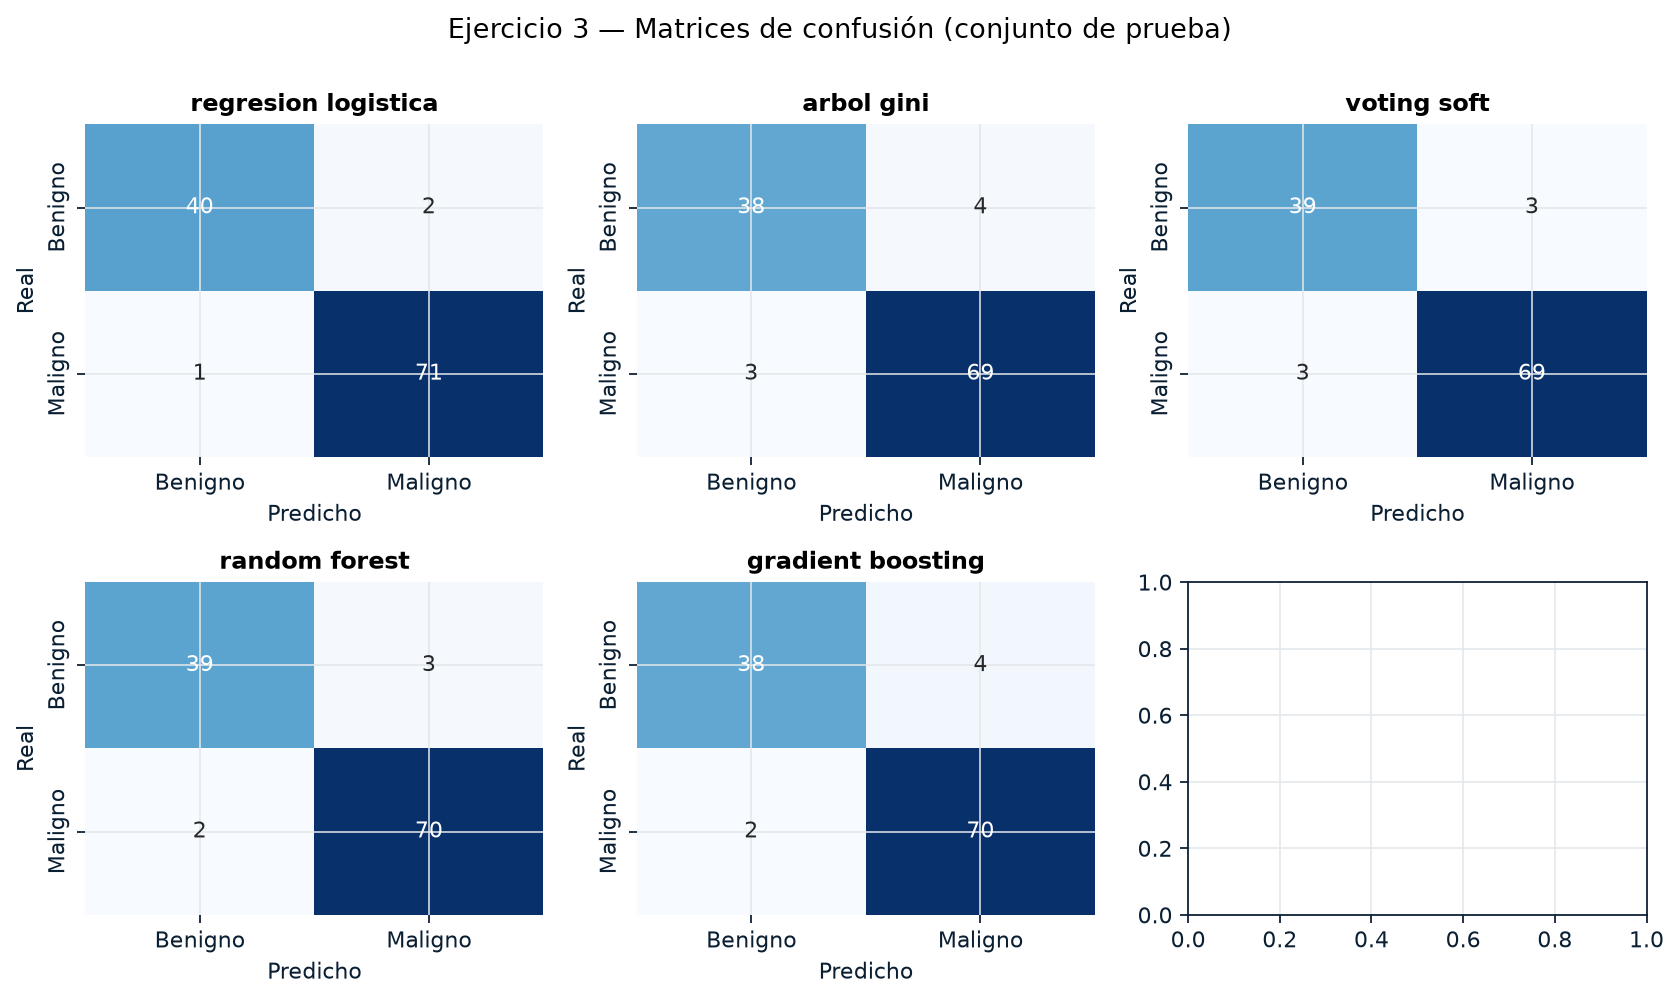

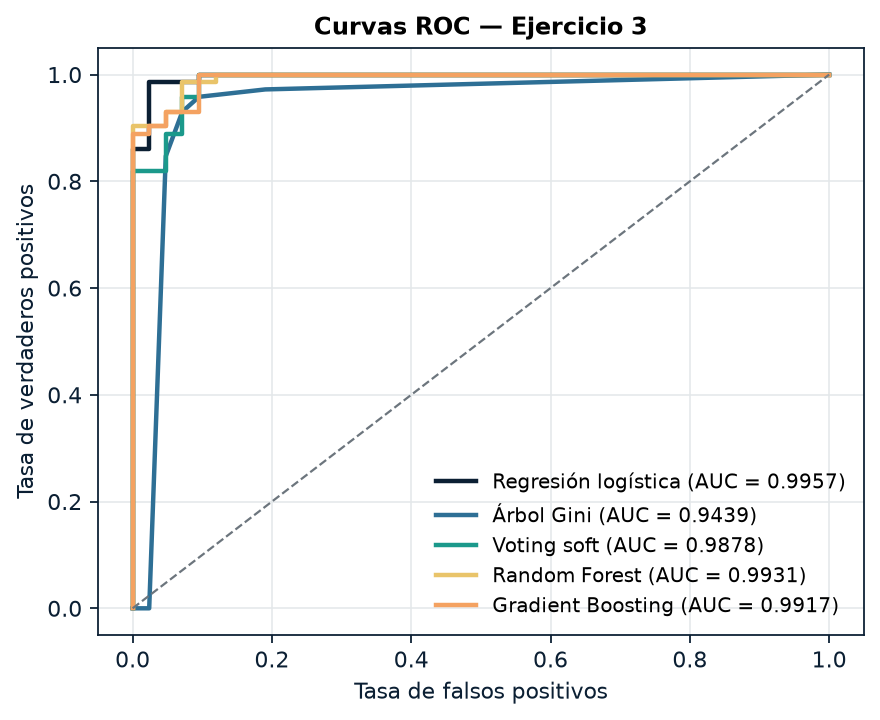

In [8]:
etiquetas_ej3 = ["Regresión\nlogística", "Árbol\nGini", "Voting\nsoft", "Random\nForest", "Gradient\nBoosting"]
claves_ej3 = ["regresion_logistica", "arbol_gini", "voting_soft", "random_forest", "gradient_boosting"]
colores_ej3 = [PALETA["azul_profundo"], PALETA["azul_claro"], PALETA["turquesa"],
               PALETA["ambar"], PALETA["naranja"]]

fig, axes = plt.subplots(1, 3, figsize=(11.6, 3.8))

for ax, metrica, titulo in zip(axes, ["exactitud", "f1", "auc_roc"],
                                ["Exactitud", "F1", "AUC-ROC"]):
    valores = [metricas_ej3.loc[k, metrica] for k in claves_ej3]
    barras = ax.bar(etiquetas_ej3, valores, color=colores_ej3, width=0.6, edgecolor="white")
    ax.bar_label(barras, fmt="%.4f", fontsize=8.5, padding=2)
    ax.set_title(titulo)
    ax.set_ylim(0.6, 1.02)
    ax.grid(axis="x", visible=False)

fig.suptitle("Ejercicio 3 — Modelo individual frente a modelos ensemble", y=1.02, fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "grafico_17_metricas_ejercicio3.png")
plt.show()
plt.close(fig)

fig, axes = plt.subplots(2, 3, figsize=(10.6, 6.2))
for ax, clave in zip(axes.ravel(), claves_ej3):
    y_pred = modelos_ej3[clave].predict(X_te)
    cm = confusion_matrix(y_te, y_pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Benigno", "Maligno"], yticklabels=["Benigno", "Maligno"])
    ax.set_title(clave.replace("_", " "))
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")

fig.suptitle("Ejercicio 3 — Matrices de confusión (conjunto de prueba)", y=1.0, fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "grafico_18_matrices_confusion_ejercicio3.png")
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(5.6, 4.6))
for clave, color, etiqueta in zip(claves_ej3, colores_ej3, etiquetas_ej3):
    y_prob = modelos_ej3[clave].predict_proba(X_te)[:, 1]
    fpr, tpr, _ = roc_curve(y_te, y_prob)
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f"{etiqueta.replace(chr(10), ' ')} "
                                                     f"(AUC = {metricas_ej3.loc[clave, 'auc_roc']:.4f})")
ax.plot([0, 1], [0, 1], linestyle="--", color=PALETA["gris"], linewidth=1)
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos")
ax.set_title("Curvas ROC — Ejercicio 3")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG / "grafico_19_curvas_roc_ejercicio3.png")
plt.show()
plt.close(fig)

## Parte II — Ejercicio 4: bagging frente al modelo individual

### 4.1 Datos de regresión (`auto_mpg`)

Se recupera el conjunto `auto_mpg` (UCI, 398 vehículos) con la misma partición del ejercicio 2:
**318** observaciones de entrenamiento y **80** de prueba. El preprocesamiento (imputación de la
mediana, estandarización de las variables numéricas y codificación de `origin`) se mantiene dentro
de un `Pipeline`.

In [9]:
df_am, X_am, y_am = cargar_auto_mpg()

X_tr_am, X_te_am, y_tr_am, y_te_am = train_test_split(
    X_am, y_am, test_size=0.20, random_state=SEMILLA
)

variables_numericas = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
variables_categoricas = ["origin"]

preprocesador_arbol = ColumnTransformer(
    transformers=[
        ("numericas", SimpleImputer(strategy="median"), variables_numericas),
        ("categoricas", OneHotEncoder(drop="first", handle_unknown="ignore"), variables_categoricas),
    ]
)

preprocesador_lineal = ColumnTransformer(
    transformers=[
        ("numericas", Pipeline([("imputacion", SimpleImputer(strategy="median")),
                                 ("escalador", StandardScaler())]), variables_numericas),
        ("categoricas", OneHotEncoder(drop="first", handle_unknown="ignore"), variables_categoricas),
    ]
)

cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
print(f"Auto MPG — entrenamiento: {len(X_tr_am)} | prueba: {len(X_te_am)}")

Auto MPG — entrenamiento: 318 | prueba: 80


### 4.2 Modelo individual y modelo de bagging

- **Modelo individual:** árbol de regresión con los hiperparámetros_optimos del ejercicio 2
  (criterio `absolute_error`, profundidad 6, mínimo 10 muestras por hoja).
- **Bagging:** `BaggingRegressor` que entrena 200 árboles sobre subconjuntos bootstrap del
  conjunto de entrenamiento (con `max_samples = 0.8`), y promedia sus predicciones.
- **RandomForest:** variante de bagging que además submuestrea las variables en cada árbol.
- **Referencias:** regresión lineal y regresor *dummy* (predicción media).

In [10]:
pipe_arbol_reg = Pipeline([("preprocesador", preprocesador_arbol),
                            ("arbol", DecisionTreeRegressor(random_state=SEMILLA))])
malla_arbol_reg = {
    "arbol__criterion": ["squared_error", "absolute_error"],
    "arbol__max_depth": [2, 3, 4, 5, 6, 8, None],
    "arbol__min_samples_leaf": [1, 3, 5, 10],
    "arbol__max_features": [None, 0.8],
}
busqueda_arbol_reg = GridSearchCV(pipe_arbol_reg, malla_arbol_reg, cv=cv_reg,
                                   scoring="neg_root_mean_squared_error", n_jobs=-1)
busqueda_arbol_reg.fit(X_tr_am, y_tr_am)
modelo_arbol_reg = busqueda_arbol_reg.best_estimator_
print(f"[árbol de regresión] mejor RMSE CV = {-busqueda_arbol_reg.best_score_:.4f} | "
      f"{busqueda_arbol_reg.best_params_}")

pipe_bagging = Pipeline([
    ("preprocesador", preprocesador_arbol),
    ("bagging", BaggingRegressor(
        estimator=DecisionTreeRegressor(criterion="absolute_error", max_depth=6,
                                         min_samples_leaf=10, random_state=SEMILLA),
        n_estimators=200, max_samples=0.8, random_state=SEMILLA, n_jobs=-1)),
])
malla_bagging = {"bagging__n_estimators": [50, 100, 200], "bagging__max_samples": [0.6, 0.8, 1.0]}
busqueda_bagging = GridSearchCV(pipe_bagging, malla_bagging, cv=cv_reg,
                                 scoring="neg_root_mean_squared_error", n_jobs=-1)
t0 = time.perf_counter()
busqueda_bagging.fit(X_tr_am, y_tr_am)
t1 = time.perf_counter()
modelo_bagging = busqueda_bagging.best_estimator_
print(f"[bagging] mejor RMSE CV = {-busqueda_bagging.best_score_:.4f} | "
      f"{busqueda_bagging.best_params_} | tiempo = {t1 - t0:.2f} s")

pipe_rf_reg = Pipeline([("preprocesador", preprocesador_arbol),
                        ("bosque", RandomForestRegressor(random_state=SEMILLA, n_jobs=-1))])
malla_rf_reg = {
    "bosque__n_estimators": [100, 300],
    "bosque__max_depth": [None, 6, 10],
    "bosque__min_samples_leaf": [1, 3],
    "bosque__max_features": [1.0, 0.8],
}
busqueda_rf_reg = GridSearchCV(pipe_rf_reg, malla_rf_reg, cv=cv_reg,
                               scoring="neg_root_mean_squared_error", n_jobs=-1)
t0 = time.perf_counter()
busqueda_rf_reg.fit(X_tr_am, y_tr_am)
t1 = time.perf_counter()
modelo_rf_reg = busqueda_rf_reg.best_estimator_
print(f"[random forest regresión] mejor RMSE CV = {-busqueda_rf_reg.best_score_:.4f} | "
      f"{busqueda_rf_reg.best_params_} | tiempo = {t1 - t0:.2f} s")

pipe_lineal = Pipeline([("preprocesador", preprocesador_lineal),
                        ("regresor", LinearRegression())])
pipe_lineal.fit(X_tr_am, y_tr_am)

dummy_reg = Pipeline([("preprocesador", preprocesador_arbol),
                       ("regresor", DummyRegressor(strategy="mean"))])
dummy_reg.fit(X_tr_am, y_tr_am)

[árbol de regresión] mejor RMSE CV = 3.3393 | {'arbol__criterion': 'absolute_error', 'arbol__max_depth': 6, 'arbol__max_features': None, 'arbol__min_samples_leaf': 10}


[bagging] mejor RMSE CV = 3.1842 | {'bagging__max_samples': 1.0, 'bagging__n_estimators': 200} | tiempo = 2.31 s


[random forest regresión] mejor RMSE CV = 2.9724 | {'bosque__max_depth': 10, 'bosque__max_features': 0.8, 'bosque__min_samples_leaf': 1, 'bosque__n_estimators': 300} | tiempo = 5.75 s


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesador', ...), ('regresor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['cylinders','displacement','horsepower',...,'acceleration','model_year', 'origin']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed thr

### 4.3 Evaluación sobre el conjunto de prueba y validación repetida

Además de la evaluación puntual, se repite el protocolo con **7 particiones 80/20** distintas.
Esta repetición es la clave del ejercicio: el bagging reduce la **varianza** del estimador, por
lo que se espera un RMSE medio menor y, sobre todo, una dispersión menor entre particiones.

In [11]:
modelos_ej4 = {
    "arbol_individual": modelo_arbol_reg,
    "bagging_arboles": modelo_bagging,
    "random_forest": modelo_rf_reg,
    "regresion_lineal": pipe_lineal,
    "dummy_media": dummy_reg,
}


def evaluar_regresor(nombre, estimador, X_ent, y_ent, X_pru, y_pru):
    y_pred = estimador.predict(X_pru)
    y_pred_ent = estimador.predict(X_ent)
    return {
        "modelo": nombre,
        "rmse": float(np.sqrt(mean_squared_error(y_pru, y_pred))),
        "mae": float(mean_absolute_error(y_pru, y_pred)),
        "r2": float(r2_score(y_pru, y_pred)),
        "rmse_entrenamiento": float(np.sqrt(mean_squared_error(y_ent, y_pred_ent))),
        "mae_entrenamiento": float(mean_absolute_error(y_ent, y_pred_ent)),
        "r2_entrenamiento": float(r2_score(y_ent, y_pred_ent)),
    }


filas_ej4 = [evaluar_regresor(nombre, est, X_tr_am, y_tr_am, X_te_am, y_te_am)
             for nombre, est in modelos_ej4.items()]
metricas_ej4 = pd.DataFrame(filas_ej4).set_index("modelo")
print(metricas_ej4.round(4).to_string())
guardar_csv(metricas_ej4.reset_index(), "ejercicio4_metricas.csv")

registros_ej4 = []
for semilla in semillas:
    tr, te, y_tr_s, y_te_s = train_test_split(X_am, y_am, test_size=0.20, random_state=semilla)
    for nombre, estimador in modelos_ej4.items():
        copia = clone(estimador).fit(tr, y_tr_s)
        predicciones = copia.predict(te)
        registros_ej4.append({
            "semilla": semilla,
            "modelo": nombre,
            "rmse": float(np.sqrt(mean_squared_error(y_te_s, predicciones))),
            "mae": float(mean_absolute_error(y_te_s, predicciones)),
            "r2": float(r2_score(y_te_s, predicciones)),
        })

tabla_rep_ej4 = pd.DataFrame(registros_ej4)
resumen_rep_ej4 = tabla_rep_ej4.groupby("modelo").agg(
    rmse_media=("rmse", "mean"), rmse_de=("rmse", "std"),
    rmse_min=("rmse", "min"), rmse_max=("rmse", "max"),
    r2_media=("r2", "mean"), r2_de=("r2", "std"),
).round(4)
print("\nValidación repetida (7 particiones 80/20 con semillas distintas):")
print(resumen_rep_ej4.to_string())
guardar_csv(tabla_rep_ej4, "ejercicio4_repeticiones.csv")

                    rmse     mae      r2  rmse_entrenamiento  mae_entrenamiento  r2_entrenamiento
modelo                                                                                           
arbol_individual  2.5700  1.8850  0.8772              2.5948             1.7006            0.8926
bagging_arboles   2.4901  1.8769  0.8847              2.7150             1.8390            0.8824
random_forest     2.1579  1.5992  0.9134              1.1138             0.7818            0.9802
regresion_lineal  2.8877  2.2882  0.8449              3.3697             2.6046            0.8189
dummy_media       7.3473  5.9554 -0.0040              7.9181             6.6847            0.0000



Validación repetida (7 particiones 80/20 con semillas distintas):
                  rmse_media  rmse_de  rmse_min  rmse_max  r2_media   r2_de
modelo                                                                     
arbol_individual      3.0976   0.6492    2.3807    4.2307    0.8188  0.0941
bagging_arboles       2.8879   0.6141    2.0324    3.8686    0.8426  0.0790
dummy_media           7.5194   0.3120    6.9037    7.8750   -0.0073  0.0098
random_forest         2.7300   0.6449    2.0876    3.8487    0.8576  0.0820
regresion_lineal      3.3506   0.3734    2.8877    3.7327    0.7973  0.0462


PosixPath('/home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 3/resultados/ejercicio4_repeticiones.csv')

### 4.4 Comprobación en clasificación

Para completar el ejercicio se repite la comparación de bagging con un clasificador sobre
`breast_cancer`: el `BaggingClassifier` se apoya en el mejor árbol individual del ejercicio 3.

In [12]:
modelo_bagging_clf = BaggingClassifier(
    estimator=DecisionTreeClassifier(criterion="gini", max_depth=3, min_samples_leaf=5,
                                      random_state=SEMILLA),
    n_estimators=200, max_samples=0.8, random_state=SEMILLA, n_jobs=-1,
)
modelo_bagging_clf.fit(X_tr, y_tr)

modelos_ej4_clf = {
    "arbol_individual": modelos_ej3["arbol_gini"],
    "bagging_arboles": modelo_bagging_clf,
    "random_forest": modelos_ej3["random_forest"],
    "regresion_logistica": modelos_ej3["regresion_logistica"],
}
filas_ej4_clf = [evaluar_clasificador(nombre, est, X_tr, y_tr, X_te, y_te)
                 for nombre, est in modelos_ej4_clf.items()]
metricas_ej4_clf = pd.DataFrame(filas_ej4_clf).set_index("modelo")
print("Clasificación — bagging frente al modelo individual (conjunto de prueba):")
print(metricas_ej4_clf.round(4).to_string())
guardar_csv(metricas_ej4_clf.reset_index(), "ejercicio4_metricas_clasificacion.csv")

Clasificación — bagging frente al modelo individual (conjunto de prueba):
                     exactitud  precision  exhaustividad      f1  auc_roc  f1_entrenamiento  accuracy_entrenamiento
modelo                                                                                                             
arbol_individual        0.9386     0.9452         0.9583  0.9517   0.9439            0.9792                  0.9736
bagging_arboles         0.9474     0.9583         0.9583  0.9583   0.9917            0.9826                  0.9780
random_forest           0.9561     0.9589         0.9722  0.9655   0.9931            1.0000                  1.0000
regresion_logistica     0.9737     0.9726         0.9861  0.9793   0.9957            0.9895                  0.9868


PosixPath('/home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 3/resultados/ejercicio4_metricas_clasificacion.csv')

### 4.5 Respuesta al ejercicio 4

Se comparan los tres indicadores: error de prueba, estabilidad entre particiones y capacidad de
generalización (coeficiente de determinación).

In [13]:
arb4 = metricas_ej4.loc["arbol_individual"]
bag4 = metricas_ej4.loc["bagging_arboles"]
rf4 = metricas_ej4.loc["random_forest"]
lin4 = metricas_ej4.loc["regresion_lineal"]

print("=" * 78)
print("PREGUNTA 4 — Bagging vs. modelo individual (regresión, conjunto de prueba)")
print("=" * 78)
print(f"RMSE de prueba:  bagging {bag4.rmse:.4f} | árbol individual {arb4.rmse:.4f} "
      f"| random forest {rf4.rmse:.4f} | lineal {lin4.rmse:.4f} | dummy {metricas_ej4.loc['dummy_media', 'rmse']:.4f}")
print(f"MAE de prueba:   bagging {bag4.mae:.4f} | árbol individual {arb4.mae:.4f}")
print(f"R² de prueba:    bagging {bag4.r2:.4f} | árbol individual {arb4.r2:.4f}")
print(f"Mejora del bagging sobre el árbol individual: "
      f"{100 * (arb4.rmse - bag4.rmse) / arb4.rmse:+.2f} % en RMSE")

print("\nEstabilidad del RMSE en 7 particiones 80/20:")
for nombre in modelos_ej4:
    fila = resumen_rep_ej4.loc[nombre]
    print(f"  {nombre:<20} {fila.rmse_media:.4f} ± {fila.rmse_de:.4f}  "
          f"[{fila.rmse_min:.4f} – {fila.rmse_max:.4f}]  R² medio = {fila.r2_media:.4f}")

print("\nClasificación (breast_cancer):")
for nombre in modelos_ej4_clf:
    fila = metricas_ej4_clf.loc[nombre]
    print(f"  {nombre:<20} F1 = {fila.f1:.4f} | exactitud = {fila.exactitud:.4f} "
          f"| AUC-ROC = {fila.auc_roc:.4f}")

PREGUNTA 4 — Bagging vs. modelo individual (regresión, conjunto de prueba)
RMSE de prueba:  bagging 2.4901 | árbol individual 2.5700 | random forest 2.1579 | lineal 2.8877 | dummy 7.3473
MAE de prueba:   bagging 1.8769 | árbol individual 1.8850
R² de prueba:    bagging 0.8847 | árbol individual 0.8772
Mejora del bagging sobre el árbol individual: +3.11 % en RMSE

Estabilidad del RMSE en 7 particiones 80/20:
  arbol_individual     3.0976 ± 0.6492  [2.3807 – 4.2307]  R² medio = 0.8188
  bagging_arboles      2.8879 ± 0.6141  [2.0324 – 3.8686]  R² medio = 0.8426
  random_forest        2.7300 ± 0.6449  [2.0876 – 3.8487]  R² medio = 0.8576
  regresion_lineal     3.3506 ± 0.3734  [2.8877 – 3.7327]  R² medio = 0.7973
  dummy_media          7.5194 ± 0.3120  [6.9037 – 7.8750]  R² medio = -0.0073

Clasificación (breast_cancer):
  arbol_individual     F1 = 0.9517 | exactitud = 0.9386 | AUC-ROC = 0.9439
  bagging_arboles      F1 = 0.9583 | exactitud = 0.9474 | AUC-ROC = 0.9917
  random_forest      

### 4.6 Figuras del ejercicio 4

**Figura 20.** Métricas de regresión y dispersión del RMSE en las 7 particiones.
**Figura 21.** Predicciones frente a valores observados y residuos del modelo de bagging.

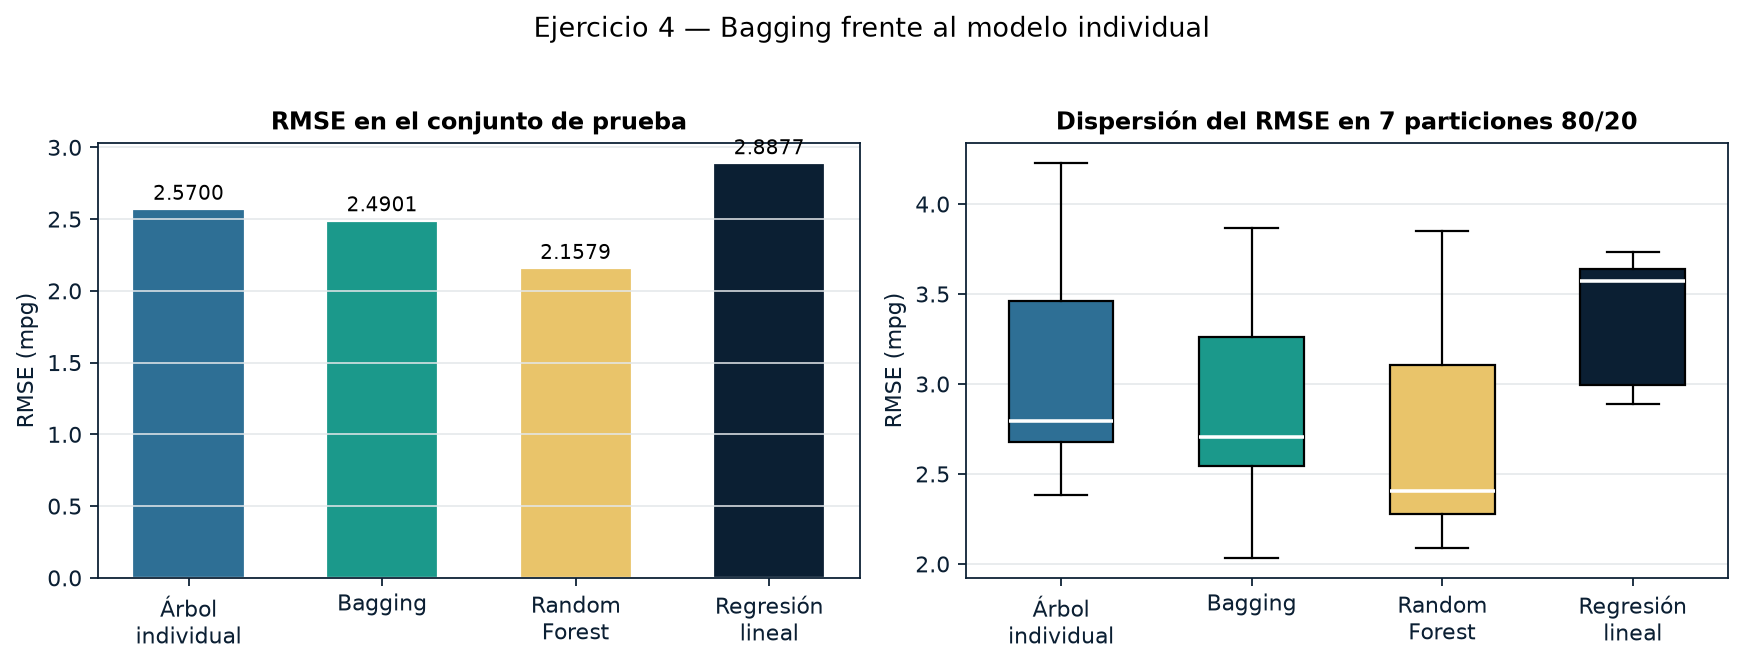

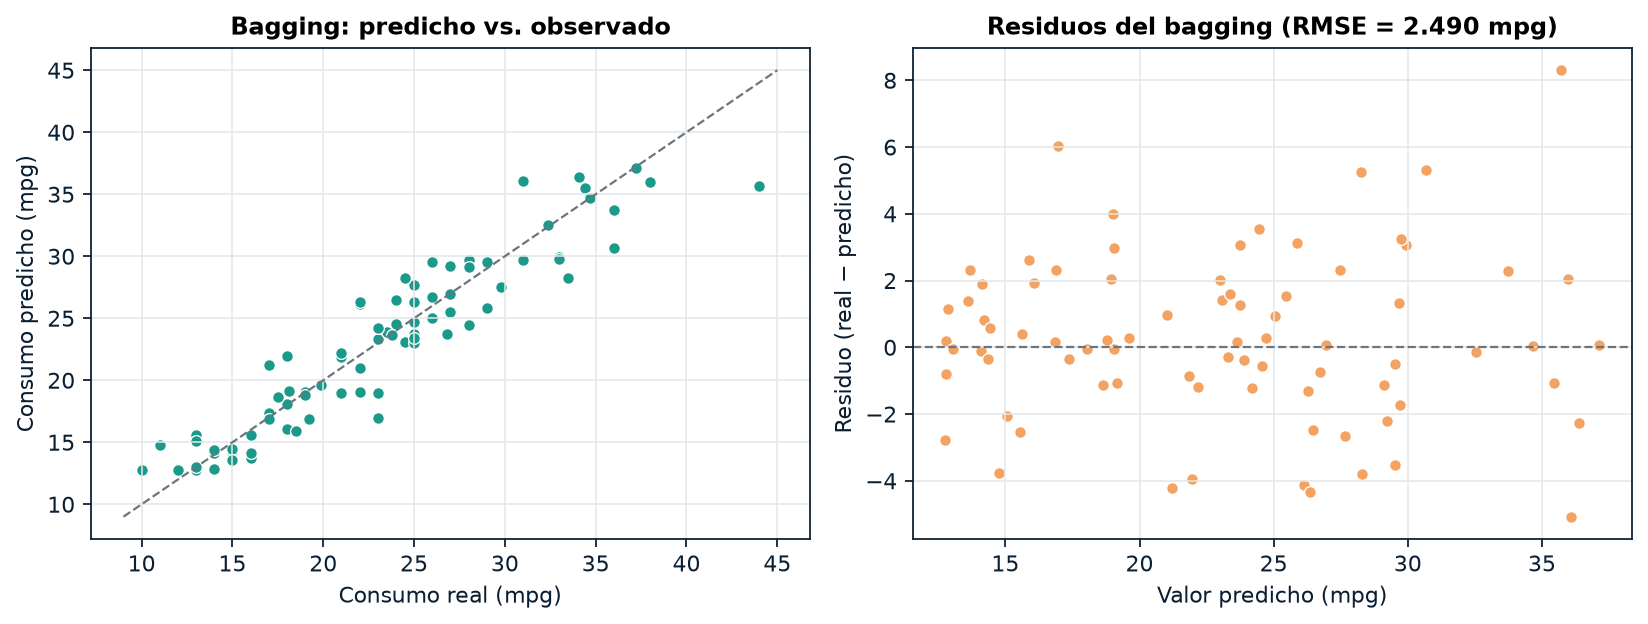

In [14]:
etiquetas_ej4 = ["Árbol\nindividual", "Bagging", "Random\nForest", "Regresión\nlineal"]
claves_ej4 = ["arbol_individual", "bagging_arboles", "random_forest", "regresion_lineal"]
colores_ej4 = [PALETA["azul_claro"], PALETA["turquesa"], PALETA["ambar"], PALETA["azul_profundo"]]

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.0))

ax = axes[0]
valores = [metricas_ej4.loc[k, "rmse"] for k in claves_ej4]
barras = ax.bar(etiquetas_ej4, valores, color=colores_ej4, width=0.58, edgecolor="white")
ax.bar_label(barras, fmt="%.4f", fontsize=9, padding=2)
ax.set_title("RMSE en el conjunto de prueba")
ax.set_ylabel("RMSE (mpg)")
ax.grid(axis="x", visible=False)

ax = axes[1]
datos_box = [tabla_rep_ej4.loc[tabla_rep_ej4["modelo"] == k, "rmse"].to_numpy() for k in claves_ej4]
cajas = ax.boxplot(datos_box, tick_labels=etiquetas_ej4, patch_artist=True, widths=0.55,
                   medianprops=dict(color="white", linewidth=1.6))
for caja, color in zip(cajas["boxes"], colores_ej4):
    caja.set_facecolor(color)
ax.set_title("Dispersión del RMSE en 7 particiones 80/20")
ax.set_ylabel("RMSE (mpg)")
ax.grid(axis="x", visible=False)

fig.suptitle("Ejercicio 4 — Bagging frente al modelo individual", y=1.03, fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "grafico_20_bagging_ejercicio4.png")
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.0))

ax = axes[0]
y_pred_bag = modelo_bagging.predict(X_te_am)
ax.scatter(y_te_am, y_pred_bag, s=28, color=PALETA["turquesa"], edgecolor="white", linewidth=0.6)
limites = [min(y_te_am.min(), y_pred_bag.min()) - 1, max(y_te_am.max(), y_pred_bag.max()) + 1]
ax.plot(limites, limites, linestyle="--", color=PALETA["gris"], linewidth=1)
ax.set_xlabel("Consumo real (mpg)")
ax.set_ylabel("Consumo predicho (mpg)")
ax.set_title("Bagging: predicho vs. observado")

ax = axes[1]
residuos = y_te_am - y_pred_bag
ax.scatter(y_pred_bag, residuos, s=28, color=PALETA["naranja"], edgecolor="white", linewidth=0.6)
ax.axhline(0, linestyle="--", color=PALETA["gris"], linewidth=1)
ax.set_xlabel("Valor predicho (mpg)")
ax.set_ylabel("Residuo (real − predicho)")
ax.set_title(f"Residuos del bagging (RMSE = {bag4.rmse:.3f} mpg)")

fig.tight_layout()
fig.savefig(FIG / "grafico_21_predicciones_residuos_bagging.png")
plt.show()
plt.close(fig)

## Parte III — Ejercicio 5: RandomForest frente a XGBoost

### 5.1 Protocolo de comparación

Ambos modelos se ajustan sobre **la misma** partición de `breast_cancer` (455 entrenamiento /
114 prueba) y con el mismo esquema de búsqueda: `GridSearchCV` con 5 particiones estratificadas
y métrica F1. Se usan exactamente las mismas variables predictoras para los dos modelos, de modo
que la única diferencia sea el algoritmo de aprendizaje del ensemble.

- **RandomForest:** bagging de árboles, submuestreo de variables,criteria `gini`.
- **XGBoost:** boosting de gradientes con regularización (`reg_lambda`), submuestreo de filas
  (`subsample`) y de columnas (`colsample_bytree`), con `tree_method="hist"`.

In [15]:
modelo_rf5 = RandomForestClassifier(random_state=SEMILLA, n_jobs=-1)
malla_rf5 = {
    "n_estimators": [200, 400],
    "max_depth": [None, 4, 8],
    "min_samples_leaf": [1, 3],
    "max_features": ["sqrt", 0.5],
}

modelo_xgb5 = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=SEMILLA,
    n_jobs=-1,
    verbosity=0,
)
malla_xgb5 = {
    "n_estimators": [200, 400],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.05, 0.1, 0.2],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
}

busqueda_rf5 = GridSearchCV(modelo_rf5, malla_rf5, cv=cv_clf, scoring="f1", n_jobs=-1)
t0 = time.perf_counter()
busqueda_rf5.fit(X_tr, y_tr)
t1 = time.perf_counter()
mejor_rf5 = busqueda_rf5.best_estimator_
tiempo_rf5 = t1 - t0
print(f"[random forest] mejor F1 CV = {busqueda_rf5.best_score_:.4f} | {busqueda_rf5.best_params_} "
      f"| tiempo = {tiempo_rf5:.2f} s")

busqueda_xgb5 = GridSearchCV(modelo_xgb5, malla_xgb5, cv=cv_clf, scoring="f1", n_jobs=-1)
t0 = time.perf_counter()
busqueda_xgb5.fit(X_tr, y_tr)
t1 = time.perf_counter()
mejor_xgb5 = busqueda_xgb5.best_estimator_
tiempo_xgb5 = t1 - t0
print(f"[xgboost] mejor F1 CV = {busqueda_xgb5.best_score_:.4f} | {busqueda_xgb5.best_params_} "
      f"| tiempo = {tiempo_xgb5:.2f} s")

/home/ccunurana/Documentos/Aprendizaje Profundo/.venv/lib64/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/ccunurana/Documentos/Aprendizaje Profundo/.venv/lib64/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/ccunurana/Documentos/Aprendizaje Profundo/.venv/lib64/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib 

/home/ccunurana/Documentos/Aprendizaje Profundo/.venv/lib64/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/ccunurana/Documentos/Aprendizaje Profundo/.venv/lib64/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/ccunurana/Documentos/Aprendizaje Profundo/.venv/lib64/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib 

/home/ccunurana/Documentos/Aprendizaje Profundo/.venv/lib64/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/ccunurana/Documentos/Aprendizaje Profundo/.venv/lib64/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/ccunurana/Documentos/Aprendizaje Profundo/.venv/lib64/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib 

[random forest] mejor F1 CV = 0.9719 | {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 400} | tiempo = 14.00 s


[xgboost] mejor F1 CV = 0.9807 | {'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 400, 'subsample': 0.8} | tiempo = 11.42 s


### 5.2 Comparación en el conjunto de prueba

Además del punto de prueba, se reportan la validación cruzada de 5 particiones y 7 particiones
80/20 independientes, que son las estimaciones con menor varianza.

In [16]:
modelos_ej5 = {"random_forest": mejor_rf5, "xgboost": mejor_xgb5}

filas_ej5 = [evaluar_clasificador(nombre, est, X_tr, y_tr, X_te, y_te)
             for nombre, est in modelos_ej5.items()]
metricas_ej5 = pd.DataFrame(filas_ej5).set_index("modelo")
print(metricas_ej5.round(4).to_string())
guardar_csv(metricas_ej5.reset_index(), "ejercicio5_metricas.csv")

cv_tabla5 = []
for nombre, est in modelos_ej5.items():
    puntajes = cross_validate(est, X_tr, y_tr, cv=cv_clf,
                              scoring=["f1", "roc_auc", "accuracy"], n_jobs=-1)
    cv_tabla5.append({
        "modelo": nombre,
        "f1_cv_media": float(np.mean(puntajes["test_f1"])),
        "f1_cv_de": float(np.std(puntajes["test_f1"])),
        "auc_cv_media": float(np.mean(puntajes["test_roc_auc"])),
        "auc_cv_de": float(np.std(puntajes["test_roc_auc"])),
        "accuracy_cv_media": float(np.mean(puntajes["test_accuracy"])),
    })

tabla_cv_ej5 = pd.DataFrame(cv_tabla5).set_index("modelo")
print("\nValidación cruzada (5 particiones):")
print(tabla_cv_ej5.round(4).to_string())
guardar_csv(tabla_cv_ej5.reset_index(), "ejercicio5_cv.csv")

registros_ej5 = []
for semilla in semillas:
    X_tr_s, X_te_s, y_tr_s, y_te_s = train_test_split(
        X_bc, y_bc, test_size=0.20, random_state=semilla, stratify=y_bc
    )
    for nombre, est in modelos_ej5.items():
        copia = clone(est).fit(X_tr_s, y_tr_s)
        y_pred = copia.predict(X_te_s)
        registros_ej5.append({
            "semilla": semilla,
            "modelo": nombre,
            "f1": float(f1_score(y_te_s, y_pred, zero_division=0)),
            "exactitud": float(accuracy_score(y_te_s, y_pred)),
            "auc_roc": float(roc_auc_score(y_te_s, copia.predict_proba(X_te_s)[:, 1])),
        })

tabla_rep_ej5 = pd.DataFrame(registros_ej5)
resumen_rep_ej5 = tabla_rep_ej5.groupby("modelo").agg(
    f1_media=("f1", "mean"), f1_de=("f1", "std"),
    f1_min=("f1", "min"), f1_max=("f1", "max"),
    auc_media=("auc_roc", "mean"), auc_de=("auc_roc", "std"),
).round(4)
print("\nValidación repetida (7 particiones 80/20):")
print(resumen_rep_ej5.to_string())
guardar_csv(tabla_rep_ej5, "ejercicio5_repeticiones.csv")

               exactitud  precision  exhaustividad      f1  auc_roc  f1_entrenamiento  accuracy_entrenamiento
modelo                                                                                                       
random_forest     0.9561     0.9589         0.9722  0.9655   0.9917               1.0                     1.0
xgboost           0.9561     0.9467         0.9861  0.9660   0.9937               1.0                     1.0



Validación cruzada (5 particiones):
               f1_cv_media  f1_cv_de  auc_cv_media  auc_cv_de  accuracy_cv_media
modelo                                                                          
random_forest       0.9719    0.0116        0.9892     0.0091             0.9648
xgboost             0.9807    0.0129        0.9939     0.0048             0.9758



Validación repetida (7 particiones 80/20):
               f1_media   f1_de  f1_min  f1_max  auc_media  auc_de
modelo                                                            
random_forest    0.9683  0.0075  0.9589  0.9790     0.9911  0.0081
xgboost          0.9673  0.0112  0.9504  0.9859     0.9949  0.0036


PosixPath('/home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 3/resultados/ejercicio5_repeticiones.csv')

### 5.3 Importancia de las variables

Se comparan las importancias por impureza (RandomForest) y por ganancia (XGBoost) sobre las
diez variables más relevantes, lo que permite explicar en qué se diferencian los dos modelos.

In [17]:
imp_rf = pd.Series(mejor_rf5.feature_importances_, index=nombres_bc).sort_values(ascending=False)
imp_xgb = pd.Series(mejor_xgb5.feature_importances_, index=nombres_bc).sort_values(ascending=False)

tabla_importancias = pd.DataFrame({
    "random_forest": imp_rf,
    "xgboost": imp_xgb,
}).round(4)
print(tabla_importancias.head(10).to_string())
guardar_csv(tabla_importancias.reset_index().rename(columns={"index": "variable"}),
            "ejercicio5_importancias.csv")

                         random_forest  xgboost
area error                      0.0136   0.0125
compactness error               0.0021   0.0045
concave points error            0.0021   0.0033
concavity error                 0.0032   0.0455
fractal dimension error         0.0049   0.0052
mean area                       0.0116   0.0275
mean compactness                0.0025   0.0063
mean concave points             0.1179   0.1065
mean concavity                  0.0197   0.0072
mean fractal dimension          0.0016   0.0050


PosixPath('/home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 3/resultados/ejercicio5_importancias.csv')

### 5.4 Respuesta al ejercicio 5

In [18]:
rf5 = metricas_ej5.loc["random_forest"]
xgb5 = metricas_ej5.loc["xgboost"]

print("=" * 78)
print("PREGUNTA 5 — RandomForest vs. XGBoost (conjunto de prueba)")
print("=" * 78)
print(f"F1 de prueba:      random forest {rf5.f1:.4f} | xgboost {xgb5.f1:.4f} "
      f"| diferencia {rf5.f1 - xgb5.f1:+.4f}")
print(f"Exactitud:         random forest {rf5.exactitud:.4f} | xgboost {xgb5.exactitud:.4f}")
print(f"AUC-ROC:           random forest {rf5.auc_roc:.4f} | xgboost {xgb5.auc_roc:.4f}")
print(f"F1 CV (5 particiones): random forest {tabla_cv_ej5.loc['random_forest', 'f1_cv_media']:.4f} "
      f"| xgboost {tabla_cv_ej5.loc['xgboost', 'f1_cv_media']:.4f}")
print(f"F1 media en 7 particiones: random forest {resumen_rep_ej5.loc['random_forest', 'f1_media']:.4f} "
      f"| xgboost {resumen_rep_ej5.loc['xgboost', 'f1_media']:.4f}")
print(f"Tiempo de búsqueda: random forest {tiempo_rf5:.2f} s | xgboost {tiempo_xgb5:.2f} s")

PREGUNTA 5 — RandomForest vs. XGBoost (conjunto de prueba)
F1 de prueba:      random forest 0.9655 | xgboost 0.9660 | diferencia -0.0005
Exactitud:         random forest 0.9561 | xgboost 0.9561
AUC-ROC:           random forest 0.9917 | xgboost 0.9937
F1 CV (5 particiones): random forest 0.9719 | xgboost 0.9807
F1 media en 7 particiones: random forest 0.9683 | xgboost 0.9673
Tiempo de búsqueda: random forest 14.00 s | xgboost 11.42 s


### 5.5 Figuras del ejercicio 5

**Figura 22.** Comparación de métricas entre RandomForest y XGBoost.
**Figura 23.** Curvas ROC y matrices de confusión de ambos modelos.
**Figura 24.** Importancia de variables de RandomForest frente a XGBoost.

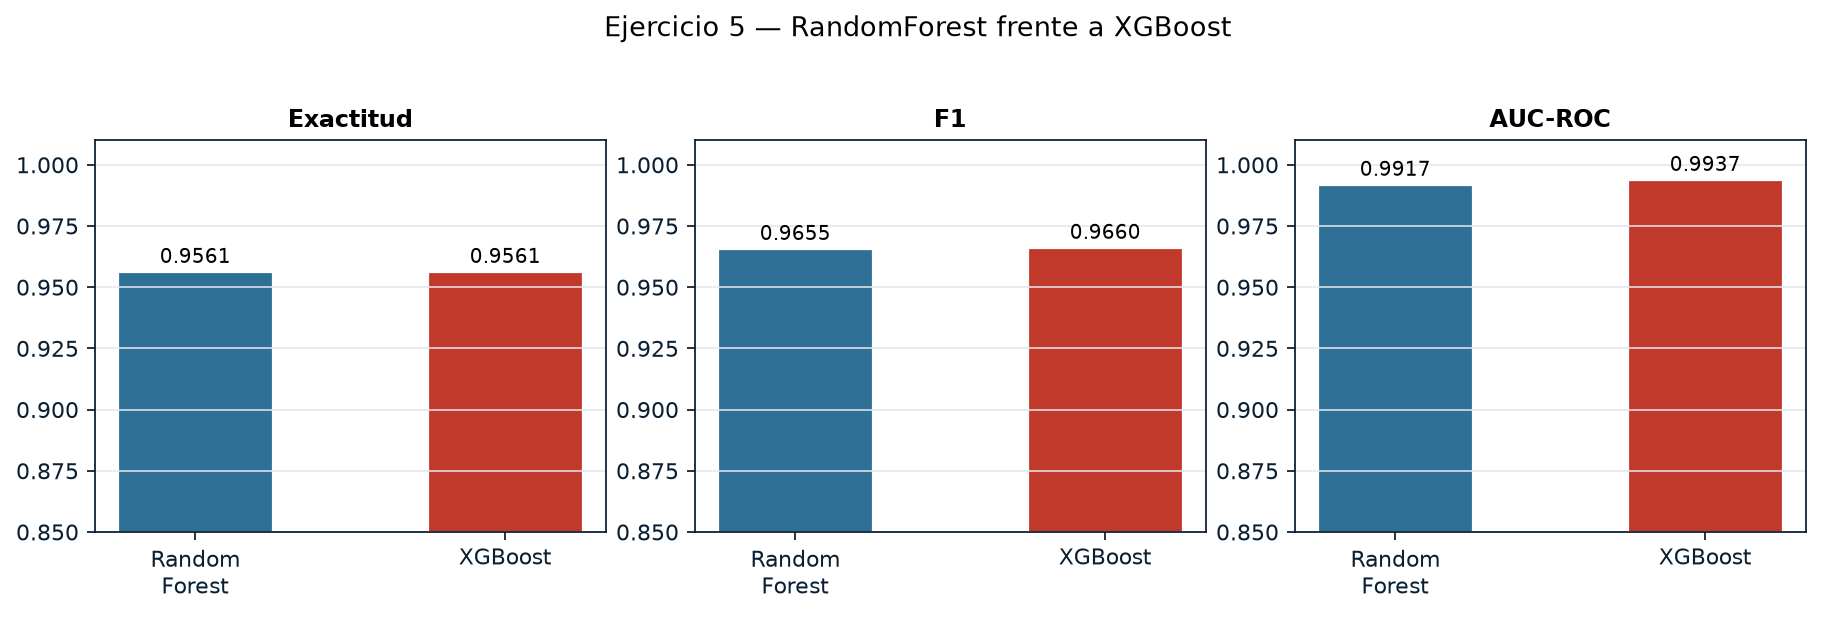

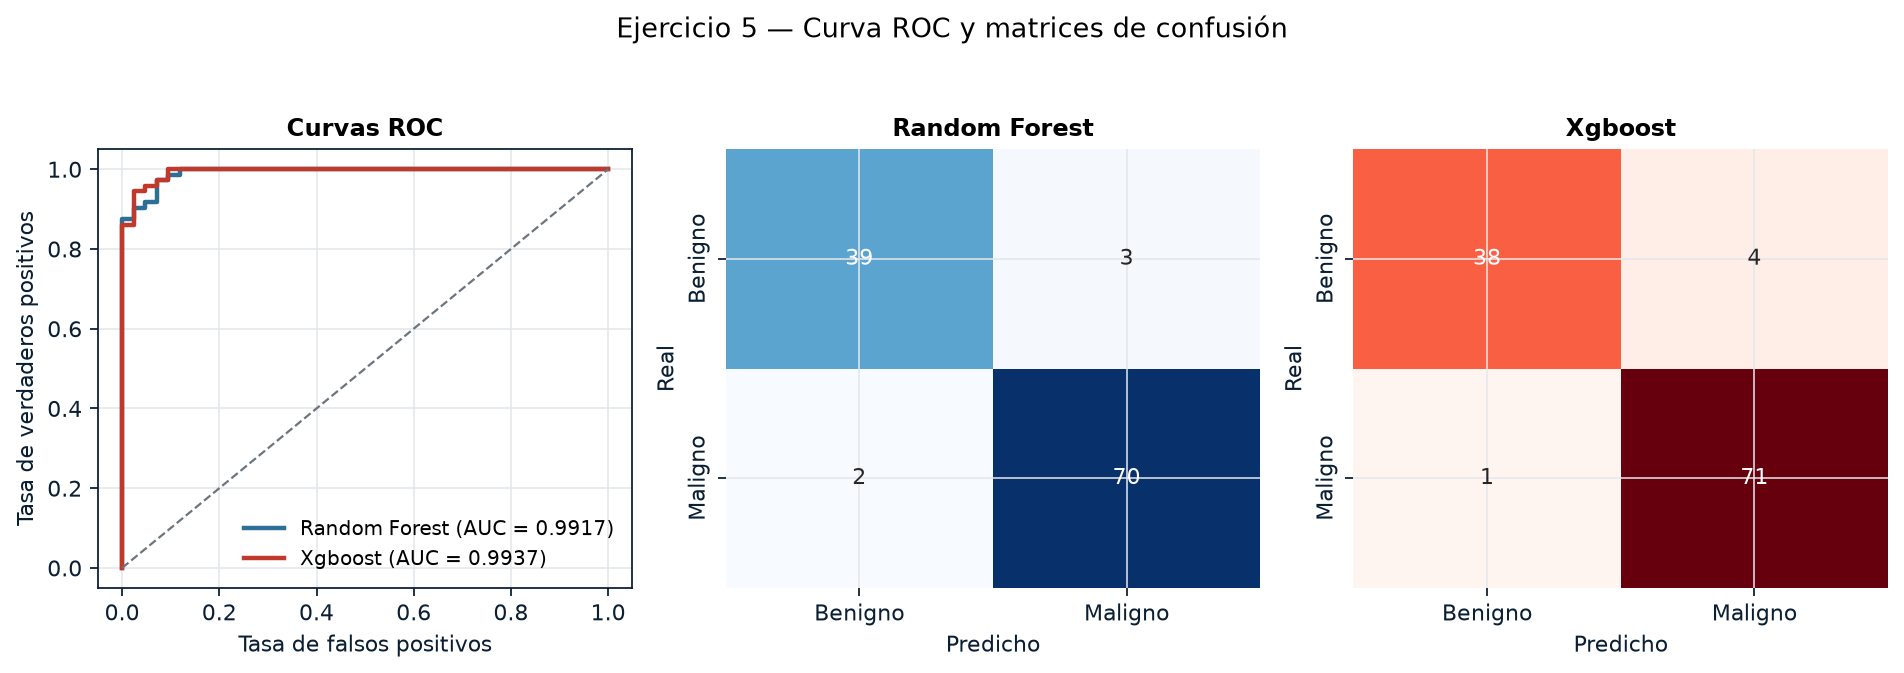

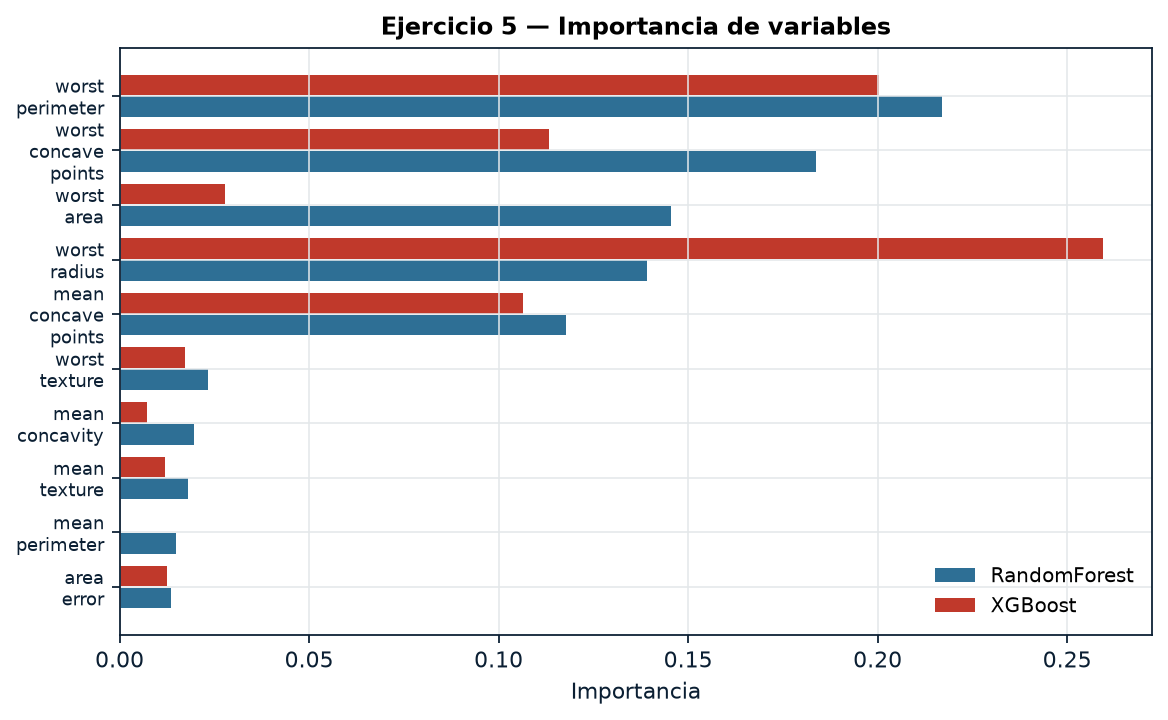

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(11.4, 3.7))
colores_ej5 = [PALETA["azul_claro"], PALETA["rojo"]]
etiquetas_ej5 = ["Random\nForest", "XGBoost"]
for ax, metrica, titulo in zip(axes, ["exactitud", "f1", "auc_roc"],
                                ["Exactitud", "F1", "AUC-ROC"]):
    valores = [metricas_ej5.loc[k, metrica] for k in modelos_ej5]
    barras = ax.bar(etiquetas_ej5, valores, color=colores_ej5, width=0.5, edgecolor="white")
    ax.bar_label(barras, fmt="%.4f", fontsize=9, padding=2)
    ax.set_title(titulo)
    ax.set_ylim(0.85, 1.01)
    ax.grid(axis="x", visible=False)

fig.suptitle("Ejercicio 5 — RandomForest frente a XGBoost", y=1.03, fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "grafico_22_randomforest_vs_xgboost.png")
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 3, figsize=(12.0, 4.0))

ax = axes[0]
for clave, color in zip(modelos_ej5, colores_ej5):
    y_prob = modelos_ej5[clave].predict_proba(X_te)[:, 1]
    fpr, tpr, _ = roc_curve(y_te, y_prob)
    ax.plot(fpr, tpr, color=color, linewidth=2,
            label=f"{clave.replace('_', ' ').title()} (AUC = {metricas_ej5.loc[clave, 'auc_roc']:.4f})")
ax.plot([0, 1], [0, 1], linestyle="--", color=PALETA["gris"], linewidth=1)
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos")
ax.set_title("Curvas ROC")
ax.legend(loc="lower right")

for ax, clave, color in zip(axes[1:], modelos_ej5, colores_ej5):
    y_pred = modelos_ej5[clave].predict(X_te)
    cm = confusion_matrix(y_te, y_pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Reds" if clave == "xgboost" else "Blues",
                cbar=False, ax=ax, xticklabels=["Benigno", "Maligno"], yticklabels=["Benigno", "Maligno"])
    ax.set_title(clave.replace("_", " ").title())
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")

fig.suptitle("Ejercicio 5 — Curva ROC y matrices de confusión", y=1.04, fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "grafico_23_roc_confusion_randomforest_xgboost.png")
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(7.4, 4.6))
top = 10
variables_top = list(imp_rf.head(top).index[::-1])
pos = np.arange(len(variables_top))
ax.barh(pos - 0.2, imp_rf[variables_top], height=0.38, color=PALETA["azul_claro"], label="RandomForest")
ax.barh(pos + 0.2, imp_xgb[variables_top], height=0.38, color=PALETA["rojo"], label="XGBoost")
ax.set_yticks(pos)
ax.set_yticklabels([v.replace(" ", "\n") for v in variables_top], fontsize=8)
ax.set_xlabel("Importancia")
ax.set_title("Ejercicio 5 — Importancia de variables")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG / "grafico_24_importancias_randomforest_xgboost.png")
plt.show()
plt.close(fig)

## Cierre del cuaderno

Se guardan en JSON los indicadores principales de los tres ejercicios, que son los que se citan
en el informe.

In [20]:
resumen_final = {
    "ejercicio_3": {
        "pregunta": "Ensemble clasificador vs. modelo individual",
        "mejor_ensemble": mejor_ensamble,
        "mejor_individual": mejor_individual,
        "metricas_prueba": metricas_ej3.round(4).to_dict(orient="index"),
        "f1_repeticiones": resumen_rep_ej3.to_dict(orient="index"),
    },
    "ejercicio_4": {
        "pregunta": "Bagging vs. modelo individual",
        "metricas_prueba": metricas_ej4.round(4).to_dict(orient="index"),
        "rmse_repeticiones": resumen_rep_ej4.to_dict(orient="index"),
        "metricas_clasificacion": metricas_ej4_clf.round(4).to_dict(orient="index"),
    },
    "ejercicio_5": {
        "pregunta": "RandomForest vs. XGBoost",
        "metricas_prueba": metricas_ej5.round(4).to_dict(orient="index"),
        "cv": tabla_cv_ej5.round(4).to_dict(orient="index"),
        "repeticiones": resumen_rep_ej5.to_dict(orient="index"),
        "mejores_parametros": {
            "random_forest": busqueda_rf5.best_params_,
            "xgboost": busqueda_xgb5.best_params_,
        },
    },
}

guardar_json(resumen_final, "resumen_ejercicios_3_4_5.json")
print("Resultados de los ejercicios 3, 4 y 5 guardados.")
print("Cuaderno 03 finalizado correctamente.")

Resultados de los ejercicios 3, 4 y 5 guardados.
Cuaderno 03 finalizado correctamente.


In [21]:
print("Figuras generadas:", sorted(p.name for p in FIG.glob("grafico_1[7-9]*.png")) +
      sorted(p.name for p in FIG.glob("grafico_2*.png")))

Figuras generadas: ['grafico_17_metricas_ejercicio3.png', 'grafico_18_matrices_confusion_ejercicio3.png', 'grafico_19_curvas_roc_ejercicio3.png', 'grafico_20_bagging_ejercicio4.png', 'grafico_21_predicciones_residuos_bagging.png', 'grafico_22_randomforest_vs_xgboost.png', 'grafico_23_roc_confusion_randomforest_xgboost.png', 'grafico_24_importancias_randomforest_xgboost.png']
